In [ ]:
!nvidia-smi

Fri Oct  9 21:04:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 1.3 Instalar ultralytics y dependencias auxiliares
!pip install -U ultralytics scikit-learn matplotlib seaborn grad-cam ttach -q

import torch, ultralytics
assert torch.cuda.is_available(), "❌ No hay GPU activa. Cambia el tipo de entorno de ejecución a GPU (T4)."
print("✅ GPU detectada:", torch.cuda.get_device_name(0))
print("Ultralytics versión:", ultralytics.__version__)
print("Torch versión:", torch.__version__, "| CUDA:", torch.version.cuda)

import pytorch_grad_cam
print("✅ pytorch_grad_cam importado con éxito.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 84.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 88.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✅ GPU detectada: Tesla

In [ ]:
import os, shutil, zipfile

# >>> RUTA DEL ZIP EN DRIVE <<<
ZIP_DRIVE_PATH = "/content/drive/MyDrive/TallerWeb/data_Alzheimer.zip"

ZIP_LOCAL_PATH = "/content/data_Alzheimer.zip"   # copia local temporal
DATA_ROOT      = "/content/data_Alzheimer"       # carpeta descomprimida

if os.path.exists(DATA_ROOT):
    print("ℹ️ El dataset ya está descomprimido en", DATA_ROOT, "(se omite este paso).")
else:
    print("Copiando ZIP desde Drive al disco local...")
    shutil.copy(ZIP_DRIVE_PATH, ZIP_LOCAL_PATH)

    print("Descomprimiendo...")
    with zipfile.ZipFile(ZIP_LOCAL_PATH) as z:
        nombres = [n for n in z.namelist() if n.strip("/") and not n.startswith("__MACOSX")]
        trae_raiz = all(n.split("/")[0] == "data_Alzheimer" for n in nombres)
        destino = "/content" if trae_raiz else DATA_ROOT
        z.extractall(destino)

# Verificación de la estructura y conteo de imágenes por carpeta
EXT = {".jpg", ".jpeg", ".png", ".bmp"}
for origen in ["OriginalDataset", "AugmentedAlzheimerDataset"]:
    print(f"\n📁 {origen}")
    base = os.path.join(DATA_ROOT, origen)
    if os.path.exists(base):
        for clase in sorted(os.listdir(base)):
            ruta = os.path.join(base, clase)
            if os.path.isdir(ruta):
                n = sum(1 for f in os.listdir(ruta) if os.path.splitext(f)[1].lower() in EXT)
                print(f"   {clase:<20} {n:>6} imágenes")

Copiando ZIP desde Drive al disco local...
Descomprimiendo...

📁 OriginalDataset
   MildDemented            896 imágenes
   ModerateDemented         64 imágenes
   NonDemented            3200 imágenes
   VeryMildDemented       2240 imágenes

📁 AugmentedAlzheimerDataset
   MildDemented           8960 imágenes
   ModerateDemented       6464 imágenes
   NonDemented            9600 imágenes
   VeryMildDemented       8960 imágenes


In [ ]:
from pathlib import Path

# ============================ PARÁMETROS DEL EXPERIMENTO ============================
YOLO_VERSION   = 'yolo26n-cls.pt'        # 'yolo26l-cls.pt' | 'yolo11l-cls.pt' | 'yolov8l-cls.pt'
DATASET_SOURCE = 'AugmentedAlzheimerDataset'       # 'OriginalDataset' | 'AugmentedAlzheimerDataset'

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.10
TEST_RATIO  = 0.20

EPOCHS     = 20
BATCH_SIZE = 16          # 16 o 32 (si te quedas sin memoria GPU, bájalo a 16)
IMAGE_SIZE = 224         # 224 píxeles (resolución estándar rápida)
SEED       = 42

EVAL_BATCH_SIZE = BATCH_SIZE

# >>> RUTA DE GUARDADO EN TU DRIVE <<<
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/TallerWeb/runs"
# ====================================================================================

RUN_NAME = f"{YOLO_VERSION.replace('.pt', '')}_{DATASET_SOURCE}_{IMAGE_SIZE}px_{EPOCHS}ep"

assert DATASET_SOURCE in ('OriginalDataset', 'AugmentedAlzheimerDataset'), "DATASET_SOURCE inválido"
assert abs((TRAIN_RATIO + VAL_RATIO + TEST_RATIO) - 1.0) < 1e-6, "Los ratios deben sumar 1.0"
os.makedirs(DRIVE_PROJECT_DIR, exist_ok=True)

print("Modelo      :", YOLO_VERSION)
print("Dataset     :", DATASET_SOURCE)
print(f"Split       : train={TRAIN_RATIO:.0%} | val={VAL_RATIO:.0%} | test={TEST_RATIO:.0%}")
print(f"Épocas/Batch: {EPOCHS} / {BATCH_SIZE}  | Resolución: {IMAGE_SIZE}px")
print("Run name    :", RUN_NAME)

Modelo      : yolo26n-cls.pt
Dataset     : AugmentedAlzheimerDataset
Split       : train=70% | val=10% | test=20%
Épocas/Batch: 20 / 16  | Resolución: 224px
Run name    : yolo26n-cls_AugmentedAlzheimerDataset_224px_20ep


In [ ]:
import random

SRC_DIR = Path(DATA_ROOT) / DATASET_SOURCE
DST_DIR = Path("/content/dataset_yolo_prepared")

if DST_DIR.exists():
    shutil.rmtree(DST_DIR)

clases = sorted(d.name for d in SRC_DIR.iterdir() if d.is_dir())
print("Clases detectadas:", clases)

rng = random.Random(SEED)
conteo = {}

for clase in clases:
    imgs = sorted(p for p in (SRC_DIR / clase).iterdir() if p.suffix.lower() in EXT)
    rng.shuffle(imgs)

    n = len(imgs)
    n_train = int(round(n * TRAIN_RATIO))
    n_val   = int(round(n * VAL_RATIO))

    particiones = {
        "train": imgs[:n_train],
        "val":   imgs[n_train:n_train + n_val],
        "test":  imgs[n_train + n_val:],
    }

    for split, lista in particiones.items():
        destino = DST_DIR / split / clase
        destino.mkdir(parents=True, exist_ok=True)
        for p in lista:
            shutil.copy2(p, destino / p.name)
        conteo[(clase, split)] = len(lista)

# Resumen en pantalla
print(f"\n{'Clase':<20}{'train':>8}{'val':>8}{'test':>8}{'total':>8}")
print("-" * 52)
tot = {"train": 0, "val": 0, "test": 0}
for clase in clases:
    fila = [conteo[(clase, s)] for s in ("train", "val", "test")]
    for s, v in zip(tot, fila):
        tot[s] += v
    print(f"{clase:<20}{fila[0]:>8}{fila[1]:>8}{fila[2]:>8}{sum(fila):>8}")
print("-" * 52)
print(f"{'TOTAL':<20}{tot['train']:>8}{tot['val']:>8}{tot['test']:>8}{sum(tot.values()):>8}")

Clases detectadas: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']

Clase                  train     val    test   total
----------------------------------------------------
MildDemented            6272     896    1792    8960
ModerateDemented        4525     646    1293    6464
NonDemented             6720     960    1920    9600
VeryMildDemented        6272     896    1792    8960
----------------------------------------------------
TOTAL                  23789    3398    6797   33984


In [ ]:
from ultralytics import YOLO

model = YOLO(YOLO_VERSION)

resultados = model.train(
    data="/content/dataset_yolo_prepared",
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMAGE_SIZE,
    project=DRIVE_PROJECT_DIR,               # Guardado en Google Drive /TallerWeb/runs
    name=RUN_NAME,
    seed=SEED,
    plots=True,
    workers=2,
    device=0,
)

SAVE_DIR = Path(model.trainer.save_dir)
print("\n✅ Entrenamiento finalizado. Resultados guardados en:", SAVE_DIR)
print("Mejor modelo:", SAVE_DIR / "weights" / "best.pt")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_yolo_prepared, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n-cls_AugmentedAlzheimerDataset_224px_20ep, nbs=

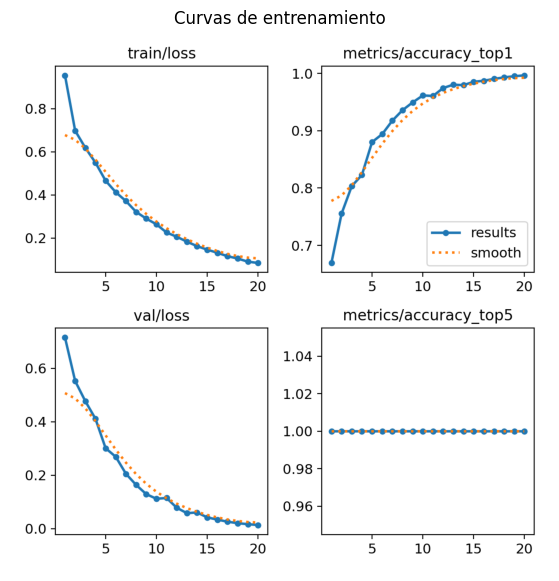

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread(SAVE_DIR / "results.png")
plt.figure(figsize=(14, 7)); plt.imshow(img); plt.axis("off")
plt.title("Curvas de entrenamiento"); plt.show()

In [ ]:
RUTA_MODELO = str(SAVE_DIR / "weights" / "best.pt")
best_model = YOLO(RUTA_MODELO)

metricas = best_model.val(
    data="/content/dataset_yolo_prepared",
    split="test",
    imgsz=IMAGE_SIZE,
    batch=EVAL_BATCH_SIZE,
    plots=True,
    project=DRIVE_PROJECT_DIR,
    name=RUN_NAME + "_test",
    exist_ok=True,
)
print(f"\n🎯 Top-1 accuracy en TEST: {metricas.top1:.4f}  ({metricas.top1 * 100:.2f}%)")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,531,148 parameters, 0 gradients, 3.2 GFLOPs
train: /content/dataset_yolo_prepared/train... found 23789 images in 4 classes ✅ 
val: /content/dataset_yolo_prepared/val... found 3398 images in 4 classes ✅ 
test: /content/dataset_yolo_prepared/test... found 6797 images in 4 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 502.3±215.5 MB/s, size: 10.0 KB)
test: Scanning /content/dataset_yolo_prepared/test... 6797 images, 0 corrupt: 100% ━━━━━━━━━━━━ 6797/6797 4.5Kit/s 1.5s
test: New cache created: /content/dataset_yolo_prepared/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 425/425 18.8it/s 22.6s
                   all      0.994          1
Speed: 0.1ms preprocess, 1.3ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/drive/MyDrive/TallerWeb/runs/yolo26n-cls_AugmentedAlzheimerDataset_224px_20ep_tes

In [ ]:
import gc
import torch
import numpy as np
from pathlib import Path

# 1. Liberar explícitamente la memoria RAM de la GPU acumulada en el Paso 5
if 'model' in globals():
    del model
gc.collect()
torch.cuda.empty_cache()

nombres = best_model.names
test_dir = Path("/content/dataset_yolo_prepared/test")

rutas, y_true = [], []
for idx, nombre in nombres.items():
    for p in sorted((test_dir / nombre).iterdir()):
        rutas.append(str(p)); y_true.append(idx)

# 2. Inferencia por minilotes manuales para no desbordar la GPU
y_pred = []
BATCH_EVAL_MANUAL = 16  # Procesa de 16 en 16 imágenes

for i in range(0, len(rutas), BATCH_EVAL_MANUAL):
    lote_rutas = rutas[i : i + BATCH_EVAL_MANUAL]
    resultados = best_model.predict(lote_rutas, imgsz=IMAGE_SIZE, verbose=False, device=0)
    for r in resultados:
        y_pred.append(int(r.probs.top1))

    # Limpiar referencias del lote en cada iteración
    del resultados
    torch.cuda.empty_cache()

gc.collect()
print(f"✅ Predicciones completadas con éxito sobre {len(y_pred)} imágenes de test.")

✅ Predicciones completadas con éxito sobre 6797 imágenes de test.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

etiquetas = [nombres[i] for i in sorted(nombres)]
print(classification_report(y_true, y_pred, target_names=etiquetas, digits=4))

                  precision    recall  f1-score   support

    MildDemented     0.9994    0.9978    0.9986      1792
ModerateDemented     1.0000    1.0000    1.0000      1293
     NonDemented     0.9906    0.9885    0.9896      1920
VeryMildDemented     0.9861    0.9900    0.9880      1792

        accuracy                         0.9935      6797
       macro avg     0.9940    0.9941    0.9941      6797
    weighted avg     0.9935    0.9935    0.9935      6797



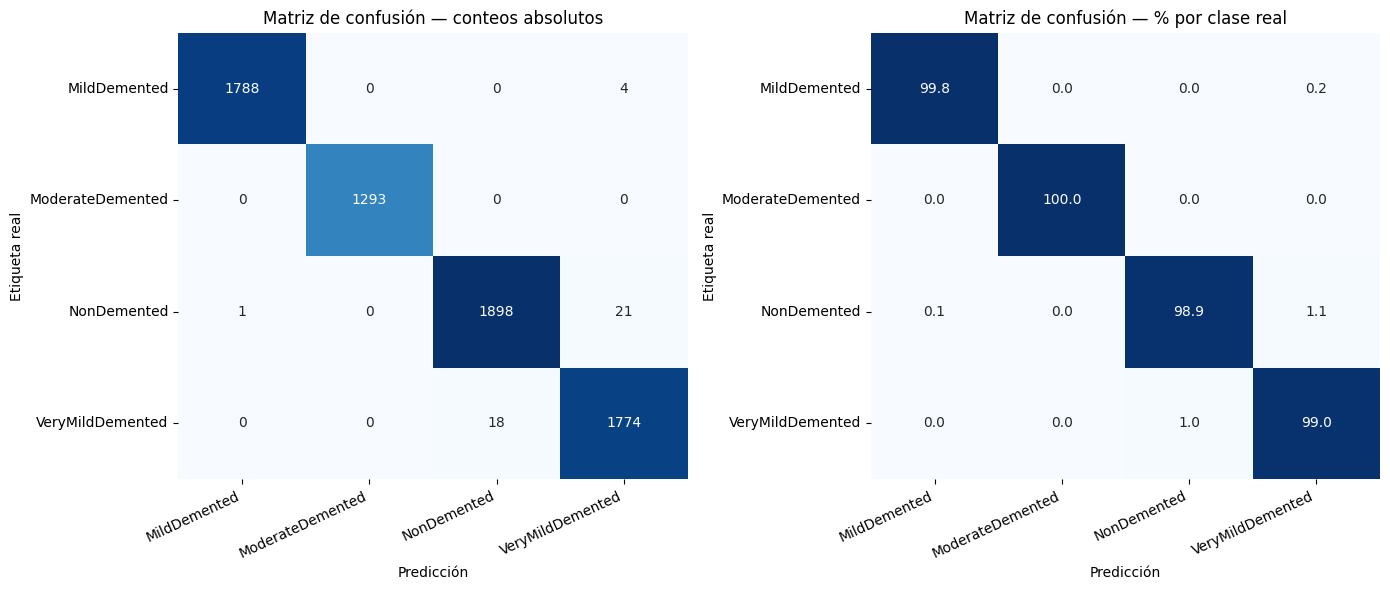

In [ ]:
import seaborn as sns

cm = confusion_matrix(y_true, y_pred, labels=sorted(nombres))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[0])
axes[0].set_title("Matriz de confusión — conteos absolutos")
axes[0].set_xlabel("Predicción"); axes[0].set_ylabel("Etiqueta real")

sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[1])
axes[1].set_title("Matriz de confusión — % por clase real")
axes[1].set_xlabel("Predicción"); axes[1].set_ylabel("Etiqueta real")

for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")

plt.tight_layout(); plt.show()

In [ ]:
# 7.1 Preparación del modelo para Grad-CAM con activación de gradientes
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from torchvision import transforms as T
from PIL import Image

modelo_gradcam = YOLO(RUTA_MODELO)
torch_model = modelo_gradcam.model.to("cuda").eval()

# FIX: Reactivar el cálculo de gradientes en los parámetros del modelo para Grad-CAM
for param in torch_model.parameters():
    param.requires_grad = True

# Envoltorio para asegurar que el modelo devuelva un Tensor puro
class YOLOClsWrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)
        return out[0] if isinstance(out, (tuple, list)) else out

model_wrapped = YOLOClsWrapper(torch_model)

# Selección de la última capa convolucional para Grad-CAM
CAPA_OBJETIVO = [torch_model.model[-2]]

preprocesar = T.Compose([T.Resize((IMAGE_SIZE, IMAGE_SIZE)), T.ToTensor()])
print("✅ Gradientes activados y Wrapper para Grad-CAM configurado correctamente.")

✅ Gradientes activados y Wrapper para Grad-CAM configurado correctamente.


In [ ]:
def diagnosticar_con_gradcam(ruta_img):
    img_pil = Image.open(ruta_img).convert("RGB")
    tensor = preprocesar(img_pil).unsqueeze(0).to("cuda")

    # 1. Obtener probabilidades de predicción
    with torch.no_grad():
        logits = model_wrapped(tensor)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    top1 = int(probs.argmax())
    diag = nombres[top1]
    conf = float(probs[top1]) * 100

    # 2. Generar mapa de calor con Grad-CAM (con gradientes habilitados)
    with torch.enable_grad():
        with GradCAM(model=model_wrapped, target_layers=CAPA_OBJETIVO) as cam:
            mapa_calor = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(top1)])[0]

    img_np = np.array(img_pil.resize((IMAGE_SIZE, IMAGE_SIZE))).astype(np.float32) / 255.0
    if img_np.ndim == 2:
        img_np = np.stack([img_np] * 3, axis=-1)
    superpuesta = show_cam_on_image(img_np, mapa_calor, use_rgb=True)

    # 3. Graficar comparativa visual de 3 paneles
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5))

    ax1.imshow(img_np); ax1.axis("off"); ax1.set_title("Imagen original")
    ax2.imshow(superpuesta); ax2.axis("off"); ax2.set_title("Grad-CAM (zonas de atención)")

    colores = ["#2a9d8f" if i == top1 else "#b0b0b0" for i in range(len(probs))]
    barras = ax3.bar(etiquetas, probs * 100, color=colores)
    ax3.set_ylim(0, 105); ax3.set_ylabel("Probabilidad (%)")
    ax3.set_title("Probabilidades por clase")
    plt.setp(ax3.get_xticklabels(), rotation=20, ha="right")
    for b, p in zip(barras, probs):
        ax3.text(b.get_x() + b.get_width() / 2, p * 100 + 1.5, f"{p * 100:.1f}%", ha="center", fontsize=9)

    fig.suptitle(f"Diagnóstico: {diag}   |   Confianza: {conf:.2f}%", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

    print(f"🧠 Grado de demencia diagnosticado: {diag}  |  Confianza: {conf:.2f}%")

In [ ]:
# Cargas el mejor modelo guardado en Drive de la sesión anterior
from pathlib import Path
model = YOLO('/content/drive/MyDrive/TallerWeb/runs/yolo26l-cls_AugmentedAlzheimerDataset_224px_50ep/weights/best.pt')

Saving non_32.jpg to non_32.jpg


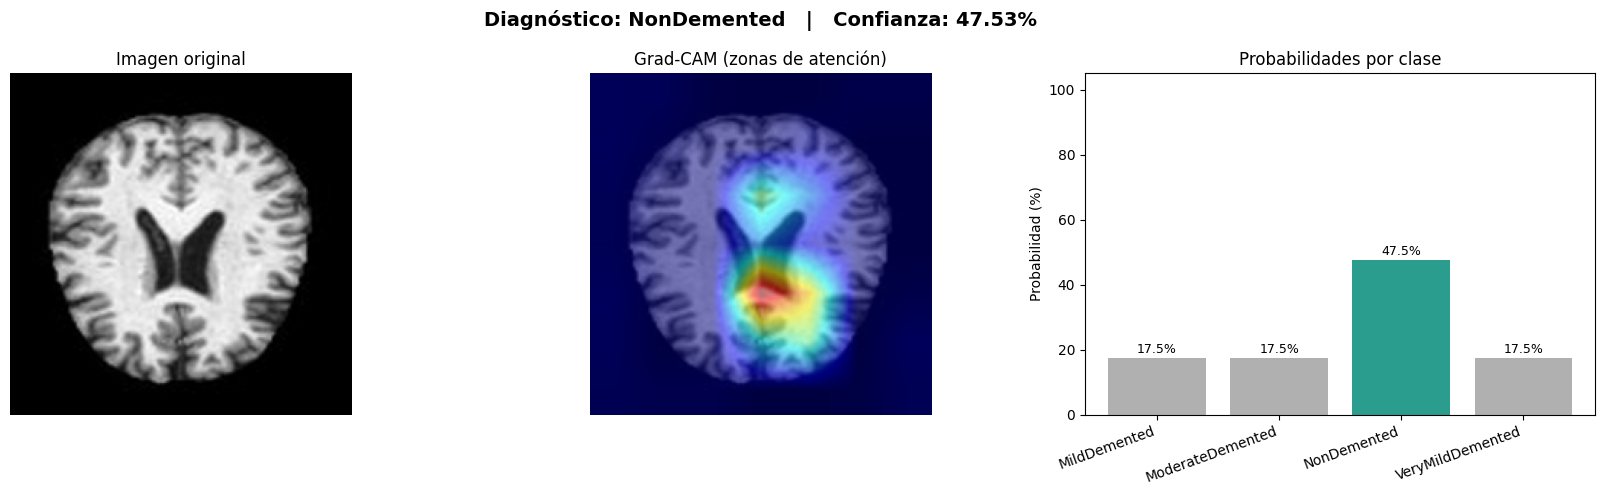

🧠 Grado de demencia diagnosticado: NonDemented  |  Confianza: 47.53%


In [ ]:
from google.colab import files

MODO_CARGA = "upload"     # "upload" (subir desde PC) | "ruta" (Drive/disco local)
RUTA_IMAGEN = "/content/drive/MyDrive/TallerWeb/mi_resonancia.jpg"

if MODO_CARGA == "upload":
    subidos = files.upload()
    for nombre_archivo in subidos:
        diagnosticar_con_gradcam(os.path.abspath(nombre_archivo))
else:
    diagnosticar_con_gradcam(RUTA_IMAGEN)